# Dengue Cases in Sri Lanka: Bagging vs Boosting vs Stacking

**CM4371 Machine Learning & Pattern Recognition, Assignment 01 (Ensemble Learning Dashboard)**

**Problem.** Predict the number of dengue cases for a given **month** (per district, and for all of Sri Lanka) and forecast future months.

**Data.** Weekly dengue cases for all 25 districts, 2006-2025, with rainfall, temperature, humidity and demographic columns (Kaggle: *Dengue_Research_2006-2026*, built from the National Dengue Control Unit data).

**Models compared (only these four):**

| Role | Model | Tuning |
|---|---|---|
| Baseline | Linear Regression | **none** (no tuning, no cross-validation) |
| Bagging | Random Forest | randomised search with time-aware CV |
| Boosting | XGBoost | randomised search with time-aware CV |
| Stacking | RF + XGBoost + Ridge + KNN, blended by a Ridge meta-learner | base learners reuse the tuned RF/XGB settings |

All of the shared code (feature building, time-aware stacking, recursive forecasting) lives in `../src/pipeline.py`, so the dashboard uses exactly the same code as this notebook.

In [1]:
import sys, json, warnings, time
from pathlib import Path
sys.path.insert(0, str(Path("..") / "src"))
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, joblib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV
from xgboost import XGBRegressor

import pipeline as P

RAW = Path("../data/raw/dengue_srilanka_full_2006_2025.csv")
SEED = 42
np.random.seed(SEED)
plt.rcParams.update({"figure.figsize": (11, 3.8), "axes.grid": True, "grid.alpha": .25,
                     "axes.spines.top": False, "axes.spines.right": False})

## 1. Load and inspect the data

In [2]:
raw = P.load_raw(RAW)
print("rows x columns:", raw.shape)
display(raw.head(3))
raw.info()

rows x columns: (24775, 28)


,year,week,start.date,end.date,month,season,monsoon_season,is_epidemic_year,district,province,...,cases,incidence_rate,cases_lag1,cases_zscore,rainfall_mm,rainfall_lag2,rainfall_lag4,temp_max_c,temp_min_c,humidity_pct
0,2006,52,2006-12-23,2006-12-29,12,Maha,NE Monsoon,0,Ampara,Eastern,...,0,0.000000,NaN,-0.487808,14.5,NaN,NaN,26.9,23.300000,79.428571
1,2006,52,2006-12-23,2006-12-29,12,Maha,NE Monsoon,0,Anuradhapura,North Central,...,4,0.473990,NaN,-0.422972,2.4,NaN,NaN,27.6,21.685714,77.714286
2,2006,52,2006-12-23,2006-12-29,12,Maha,NE Monsoon,0,Badulla,Uva,...,2,0.251814,NaN,-0.541349,12.2,NaN,NaN,24.7,19.985714,87.000000


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24775 entries, 0 to 24774
Data columns (total 28 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   year                24775 non-null  int64         
 1   week                24775 non-null  int64         
 2   start.date          24775 non-null  datetime64[ns]
 3   end.date            24775 non-null  datetime64[ns]
 4   month               24775 non-null  int64         
 5   season              24775 non-null  object        
 6   monsoon_season      24775 non-null  object        
 7   is_epidemic_year    24775 non-null  int64         
 8   district            24775 non-null  object        
 9   province            24775 non-null  object        
 10  latitude            24775 non-null  float64       
 11  longitude           24775 non-null  float64       
 12  coastal_district    24775 non-null  int64         
 13  elevation_category  24775 non-null  object    

In [3]:
print("Districts          :", raw["district"].nunique())
print("Weeks              :", raw["start.date"].nunique(), f"({raw['start.date'].min().date()} -> {raw['start.date'].max().date()})")
print("Duplicate rows     :", raw.duplicated(["district", "start.date"]).sum())
miss = raw.isna().sum(); print("Missing values     :", miss[miss > 0].to_dict())
print("Negative cases     :", (raw["cases"] < 0).sum(), "| zero-case weeks:", f"{(raw['cases']==0).mean():.1%}")
display(raw[["cases", "rainfall_mm", "temp_max_c", "temp_min_c", "humidity_pct", "population"]].describe().T.round(1))

Districts          : 25
Weeks              : 991 (2006-12-23 -> 2025-12-13)
Duplicate rows     : 0
Missing values     : {'cases_lag1': 25, 'rainfall_lag2': 50, 'rainfall_lag4': 100}
Negative cases     : 0 | zero-case weeks: 13.0%


,count,mean,std,min,25%,50%,75%,max
cases,24775.0,32.4,80.7,0.0,2.0,10.0,30.0,2631.0
rainfall_mm,24775.0,38.4,48.5,0.0,6.5,22.0,53.4,647.7
temp_max_c,24775.0,29.7,3.0,16.7,28.2,29.5,31.4,38.8
temp_min_c,24775.0,23.6,2.7,7.5,22.6,24.0,25.2,29.1
humidity_pct,24775.0,80.4,7.5,50.6,75.7,82.0,86.3,97.6
population,24775.0,849851.9,602238.6,89200.0,460109.0,750727.0,1104000.0,2498473.0


**Findings.** The panel is complete (25 districts x 991 weeks, no duplicates). The only missing values are in pre-computed lag columns that the dataset author created (`cases_lag1`, `rainfall_lag2/4`), which we will not use. We build our own lags so that we control exactly what the model is allowed to see.

**Columns deliberately excluded as features (target leakage).** `incidence_rate` and `cases_zscore` are computed from `cases` itself, `is_epidemic_year` is defined from the year's case totals, and the dataset's own `cases_lag1` is a *weekly* lag. Using any of them would make the scores look better than a real forecast could be.

## 2. Exploratory analysis

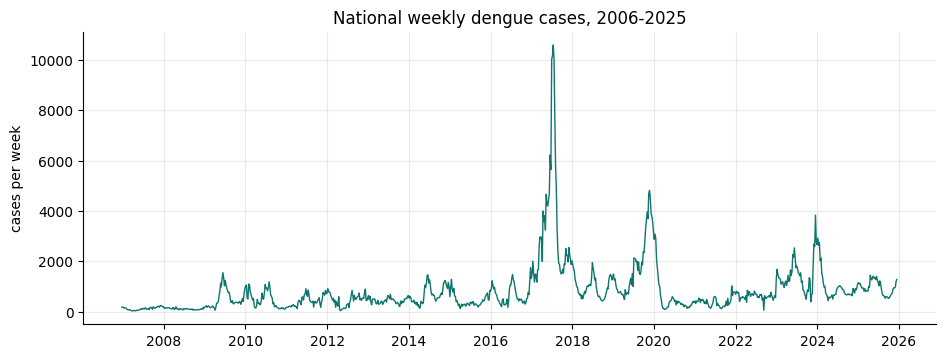

In [4]:
raw["month_start"] = raw["start.date"].dt.to_period("M").dt.to_timestamp()
weekly_nat = raw.groupby("start.date")["cases"].sum()
fig, ax = plt.subplots()
ax.plot(weekly_nat.index, weekly_nat.values, lw=1, color="#0f766e")
ax.set(title="National weekly dengue cases, 2006-2025", ylabel="cases per week")
plt.show()

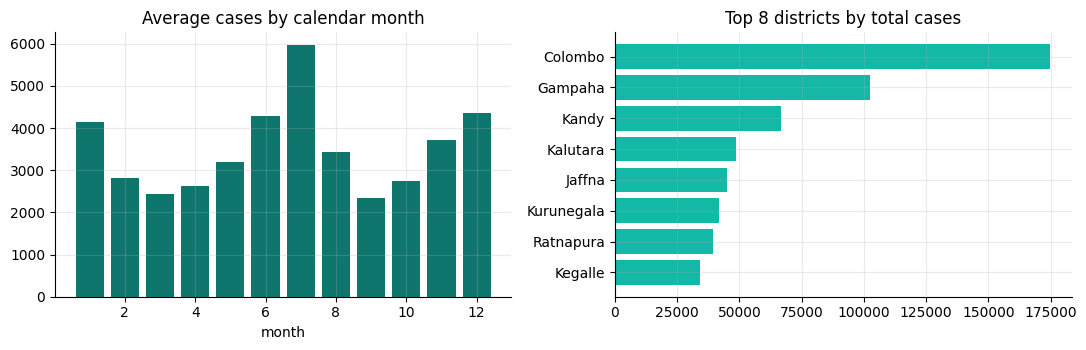

In [5]:
d = raw.assign(m=raw["start.date"].dt.month)
season = d.groupby(["year", "m"])["cases"].sum().groupby("m").mean()
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
axs[0].bar(season.index, season.values, color="#0f766e"); axs[0].set(title="Average cases by calendar month", xlabel="month")
top = raw.groupby("district")["cases"].sum().sort_values().tail(8)
axs[1].barh(top.index, top.values, color="#14b8a6"); axs[1].set(title="Top 8 districts by total cases")
plt.tight_layout(); plt.show()

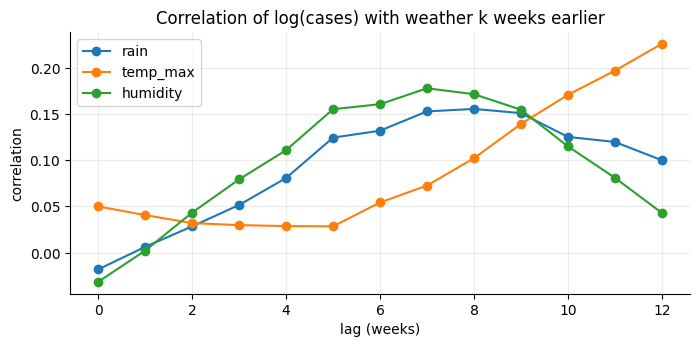

Strongest rainfall lag: 8 weeks


In [6]:
# Does rainfall lead cases?  Correlate national weekly cases with rainfall k weeks earlier.
wk = raw.groupby("start.date").agg(cases=("cases", "sum"), rain=("rainfall_mm", "mean"),
                                   tmax=("temp_max_c", "mean"), hum=("humidity_pct", "mean"))
lagc = pd.DataFrame({k: [np.log1p(wk["cases"]).corr(wk[v].shift(l)) for l in range(0, 13)]
                     for k, v in {"rain": "rain", "temp_max": "tmax", "humidity": "hum"}.items()})
fig, ax = plt.subplots(figsize=(8, 3.4)); lagc.plot(ax=ax, marker="o")
ax.set(title="Correlation of log(cases) with weather k weeks earlier", xlabel="lag (weeks)", ylabel="correlation")
plt.show()
print("Strongest rainfall lag:", int(lagc["rain"].abs().idxmax()), "weeks")

**What the EDA tells us (and what we do with it)**
* Dengue is **strongly seasonal** (monsoon months) and has rare **explosive outbreaks** (2017, 2019, 2023/24), so the target is heavily right-skewed. We model `log(1 + cases)` and convert back to cases for every metric.
* Weather matters with a **delay**, which is why only *lagged* weather is used as a feature. This also means forecasts never need future weather for the first step ahead.
* A few districts (Colombo, Gampaha, Kalutara, ...) carry most cases, so `district` and its population/location are useful features.

## 3. Monthly panel and features

The user asks about a *month* (e.g. January 2027), so weekly rows become monthly rows per district. A month has 4 or 5 weeks, so we use the weekly mean scaled to the month length (instead of a raw sum) to avoid 5-week months looking busier. The incomplete first and last months are dropped.

Every feature is a **lag of at least 1 month** (cases, national cases, rain, temperature, humidity), plus calendar (sin/cos of month) and static district information.

In [7]:
panel = P.build_monthly_panel(raw)
panel.to_csv("../data/processed/monthly_panel.csv", index=False)
print(panel.shape, "|", panel["month_start"].min().date(), "->", panel["month_start"].max().date(),
      "| months per district:", panel.groupby("district").size().unique())

feat = P.add_features(panel)
data = P.modelling_rows(feat)
data["month_idx"] = data["month_start"].dt.year * 12 + data["month_start"].dt.month
print("Modelling rows:", data.shape[0], "| features:", len(P.FEATURES))
display(data[["district", "month_start", "cases"] + P.FEATURES[:8]].head(3).round(2))

(5675, 11) | 2007-01-01 -> 2025-11-01 | months per district: [227]
Modelling rows: 5375 | features: 24


,district,month_start,cases,month_sin,month_cos,lcases_lag1,lcases_lag2,lcases_lag3,lcases_lag6,lcases_lag12,lcases_roll3
0,Ampara,2008-01-01,2.21,0.50,0.87,1.02,1.15,0.00,0.0,0.00,0.72
1,Ampara,2008-02-01,5.18,0.87,0.50,1.17,1.02,1.15,0.0,0.69,1.11
2,Ampara,2008-03-01,6.20,1.00,0.00,1.82,1.17,1.02,0.0,0.00,1.34


## 4. Chronological train / test split

Time series must **never be shuffled**. The last **24 months** are held out as the test set and are not touched until the final scoring; everything earlier is training data. The test window deliberately contains the Dec 2023 - Jan 2024 surge, which is the hardest thing to predict.

In [8]:
TEST_MONTHS = 24
last_month = data["month_start"].max()
cutoff = last_month - pd.DateOffset(months=TEST_MONTHS)          # last training month
train = data[data["month_start"] <= cutoff].reset_index(drop=True)
test = data[data["month_start"] > cutoff].reset_index(drop=True)
Xtr, ytr, gtr = train[P.FEATURES], train["y"], train["month_idx"]
Xte, yte = test[P.FEATURES], test["cases"]
print(f"train: {train['month_start'].min().date()} -> {train['month_start'].max().date()}  ({len(train)} rows)")
print(f"test : {test['month_start'].min().date()} -> {test['month_start'].max().date()}  ({len(test)} rows)")
splits = list(P.month_block_splits(gtr, n_splits=4, val_len=12))
print("CV folds (expanding window): train sizes", [len(a) for a, _ in splits], "-> validate on 12 months each")

train: 2008-01-01 -> 2023-11-01  (4775 rows)
test : 2023-12-01 -> 2025-11-01  (600 rows)
CV folds (expanding window): train sizes [3575, 3875, 4175, 4475] -> validate on 12 months each


## 5. Model 1: Baseline (Linear Regression, **no tuning, no cross-validation**)
A plain linear model on the scaled features, with default settings. It cannot represent non-linear effects such as *"rain AND the right month AND a rising national wave"*, so it shows what the ensembles add.

In [9]:
baseline = make_pipeline(StandardScaler(), LinearRegression()).fit(Xtr, ytr)
print("baseline fitted on", len(Xtr), "rows (no search, no CV)")

baseline fitted on 4775 rows (no search, no CV)


## 6. Model 2: Bagging, Random Forest
Bagging trains many deep trees on bootstrap samples and averages them, which **reduces variance**. Light tuning uses the time-aware expanding-window CV defined above (scored on MAE of log-cases).

In [10]:
rf_space = {"n_estimators": [200, 300, 400], "max_depth": [None, 10, 16],
            "min_samples_leaf": [2, 3, 5, 8], "max_features": [0.33, 0.5, 0.8, 1.0]}
t0 = time.time()
rf_search = RandomizedSearchCV(RandomForestRegressor(n_jobs=-1, random_state=SEED), rf_space, n_iter=12,
                               cv=splits, scoring="neg_mean_absolute_error", random_state=SEED, n_jobs=1).fit(Xtr, ytr)
rf = rf_search.best_estimator_
print(f"RF search {time.time()-t0:.0f}s | best CV MAE (log scale): {-rf_search.best_score_:.4f}")
print(rf_search.best_params_)

RF search 42s | best CV MAE (log scale): 0.5126
{'n_estimators': 200, 'min_samples_leaf': 5, 'max_features': 0.8, 'max_depth': 10}


## 7. Model 3: Boosting, XGBoost
Boosting adds shallow trees **one after another, each fixing the previous trees' errors**, which mainly **reduces bias**. Same time-aware CV for light tuning.

In [11]:
xgb_space = {"n_estimators": [200, 400, 700], "learning_rate": [0.02, 0.05, 0.1], "max_depth": [3, 4, 6],
             "subsample": [0.7, 0.9, 1.0], "colsample_bytree": [0.6, 0.8, 1.0],
             "min_child_weight": [1, 3, 5], "reg_lambda": [1, 5]}
t0 = time.time()
xgb_search = RandomizedSearchCV(XGBRegressor(n_jobs=-1, random_state=SEED, tree_method="hist"), xgb_space, n_iter=15,
                                cv=splits, scoring="neg_mean_absolute_error", random_state=SEED, n_jobs=1).fit(Xtr, ytr)
xgb = xgb_search.best_estimator_
print(f"XGB search {time.time()-t0:.0f}s | best CV MAE (log scale): {-xgb_search.best_score_:.4f}")
print(xgb_search.best_params_)

XGB search 36s | best CV MAE (log scale): 0.5166
{'subsample': 1.0, 'reg_lambda': 1, 'n_estimators': 200, 'min_child_weight': 3, 'max_depth': 6, 'learning_rate': 0.02, 'colsample_bytree': 0.8}


## 8. Model 4: Stacking
Level-0 learners with **different inductive biases**: Random Forest (averaged deep trees), XGBoost (sequential trees), Ridge (linear trend) and KNN (local similarity). A non-negative Ridge **meta-learner** learns how much to trust each one.

The meta-learner is trained on **out-of-fold predictions produced with expanding windows** (each year-block predicted by models that only saw earlier months). sklearn's built-in `StackingRegressor` needs a partitioning CV, which would let future data leak into the meta-learner, so `TimeStacker` in `src/pipeline.py` is used instead.

In [12]:
def make_stack():
    return P.TimeStacker(estimators=[
        ("rf", rf), ("xgb", xgb),
        ("ridge", make_pipeline(StandardScaler(), Ridge(alpha=1.0))),
        ("knn", make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=7))),
    ], final_estimator=Ridge(alpha=1.0, positive=True), min_train_months=60, block=12)

t0 = time.time()
stack = make_stack().fit(Xtr, ytr, groups=gtr)
print(f"stack fitted in {time.time()-t0:.0f}s on {stack.oof_rows_} out-of-fold rows")
print("meta-learner weights:", stack.weights_, "| intercept:", round(float(stack.meta_.intercept_), 3))

stack fitted in 20s on 3275 out-of-fold rows
meta-learner weights: {'rf': np.float64(0.2246), 'xgb': np.float64(0.0187), 'ridge': np.float64(0.7672), 'knn': np.float64(0.0134)} | intercept: -0.061


## 9. Results part A: next-month accuracy on the held-out test set
Every model predicts each test month **using the real lags** (a "one-step-ahead" forecast). Metrics are in **cases** (not log-cases): MAE, RMSE, R-squared and sMAPE, at district-month level and for the national monthly total.

In [13]:
models = {"baseline": baseline, "rf": rf, "xgb": xgb, "stack": stack}
LABEL = {"baseline": "Baseline (Linear Regression)", "rf": "Bagging (Random Forest)",
         "xgb": "Boosting (XGBoost)", "stack": "Stacking (RF+XGB+Ridge+KNN)"}

def one_step(df, model):
    return P.to_cases(model.predict(df[P.FEATURES]))

test_pred = {k: one_step(test, m) for k, m in models.items()}
res_one = {}
for k, p in test_pred.items():
    nat_a = test.groupby("month_start")["cases"].sum()
    nat_p = pd.Series(p, index=test.index).groupby(test["month_start"]).sum()
    res_one[k] = {"district": P.metrics(test["cases"], p), "national": P.metrics(nat_a, nat_p)}

def table(res, level):
    return pd.DataFrame({LABEL[k]: v[level] for k, v in res.items()}).T.round(3)
display(Markdown("**District-month level (25 districts x 24 months)**")); display(table(res_one, "district"))
display(Markdown("**National monthly total (24 months)**")); display(table(res_one, "national"))

**District-month level (25 districts x 24 months)**

,MAE,RMSE,R2,sMAPE
Baseline (Linear Regression),60.208,160.984,0.696,34.867
Bagging (Random Forest),56.781,156.364,0.714,34.101
Boosting (XGBoost),56.161,155.996,0.715,33.551
Stacking (RF+XGB+Ridge+KNN),59.795,155.197,0.718,34.409


**National monthly total (24 months)**

,MAE,RMSE,R2,sMAPE
Baseline (Linear Regression),1099.480,2325.551,0.159,19.894
Bagging (Random Forest),977.935,1971.862,0.396,19.152
Boosting (XGBoost),1033.421,2053.374,0.345,20.459
Stacking (RF+XGB+Ridge+KNN),1102.692,2219.201,0.235,19.077


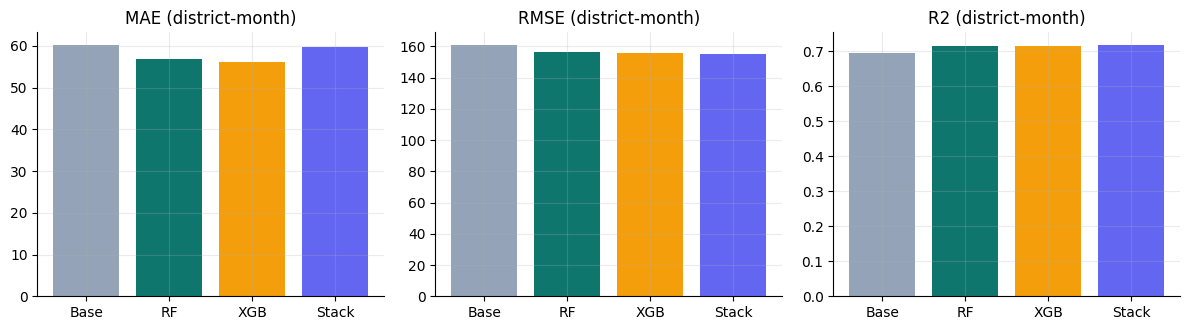

In [14]:
tab = table(res_one, "district")
fig, axs = plt.subplots(1, 3, figsize=(12, 3.4))
for ax, c in zip(axs, ["MAE", "RMSE", "R2"]):
    ax.bar(range(4), tab[c], color=["#94a3b8", "#0f766e", "#f59e0b", "#6366f1"])
    ax.set_xticks(range(4)); ax.set_xticklabels(["Base", "RF", "XGB", "Stack"]); ax.set_title(c + " (district-month)")
plt.tight_layout(); plt.show()

## 10. Results part B: real forecasting accuracy (recursive, 24 months ahead)
The dashboard's *future* forecast cannot use real lags: it predicts month 1, feeds that prediction back in to predict month 2, and so on (**recursive forecasting**), with future weather replaced by each district's historical average for that calendar month.

To measure how this behaves, we pretend the data ends at the training cut-off and forecast all 24 test months in one go with each model.

In [15]:
hist_cut = panel[panel["month_start"] <= cutoff]
clim_cut = P.make_climatology(hist_cut)
act = panel[panel["month_start"] > cutoff].set_index(["district", "month_start"])["cases"]

rec = {}
for k, m in models.items():
    f = P.recursive_forecast(m, hist_cut, TEST_MONTHS, clim_cut)
    f["actual"] = act.reindex(pd.MultiIndex.from_frame(f[["district", "month_start"]])).values
    rec[k] = f
res_multi = {}
for k, f in rec.items():
    nat = f.groupby("month_start")[["pred", "actual"]].sum()
    res_multi[k] = {"district": P.metrics(f["actual"], f["pred"]), "national": P.metrics(nat["actual"], nat["pred"])}
display(Markdown("**District-month level, 24 months ahead**")); display(table(res_multi, "district"))
display(Markdown("**National monthly total, 24 months ahead**")); display(table(res_multi, "national"))

**District-month level, 24 months ahead**

,MAE,RMSE,R2,sMAPE
Baseline (Linear Regression),107.127,246.597,0.288,63.215
Bagging (Random Forest),93.113,215.095,0.458,56.734
Boosting (XGBoost),90.344,220.060,0.433,52.333
Stacking (RF+XGB+Ridge+KNN),82.508,201.803,0.523,50.073


**National monthly total, 24 months ahead**

,MAE,RMSE,R2,sMAPE
Baseline (Linear Regression),2507.235,3278.136,-0.670,67.982
Bagging (Random Forest),1714.584,2775.436,-0.197,36.487
Boosting (XGBoost),1822.558,2906.786,-0.313,40.186
Stacking (RF+XGB+Ridge+KNN),1422.916,2595.151,-0.047,27.762


### Uncertainty ranges for the dashboard
Forecasts get worse the further ahead we look, so the dashboard shows an approximate **80% range**. It is measured, not guessed: from **12 different forecast start dates** inside the test period we forecast 12 months ahead with the (frozen) models, collect the log-errors, and group them by horizon (1-3, 4-6, 7-12 months; 13+ uses 1.25 x the 7-12 value).

In [16]:
def sigma_table(model):
    nat_err, dis_err = {}, {}
    for o in range(12):
        end = cutoff + pd.DateOffset(months=o)
        h_ = panel[panel["month_start"] <= end]
        f = P.recursive_forecast(model, h_, 12, P.make_climatology(h_))
        f["actual"] = panel.set_index(["district", "month_start"])["cases"].reindex(
            pd.MultiIndex.from_frame(f[["district", "month_start"]])).values
        f = f.dropna(subset=["actual"])
        for h, g in f.groupby("horizon"):
            b = P.horizon_bucket(h)
            dis_err.setdefault(b, []).extend(np.log((g["pred"] + 1) / (g["actual"] + 1)))
            for _, gm in g.groupby("month_start"):
                nat_err.setdefault(b, []).append(np.log((gm["pred"].sum() + 1) / (gm["actual"].sum() + 1)))
    rms = lambda d: {b: float(np.sqrt(np.mean(np.square(v)))) for b, v in d.items()}
    out = {}
    for lvl, d in (("national", rms(nat_err)), ("district", rms(dis_err))):
        d["13+"] = d["7-12"] * 1.25
        out[lvl] = d
    return out

t0 = time.time()
sigma = {k: sigma_table(m) for k, m in models.items()}
print(f"{time.time()-t0:.0f}s")
display(pd.DataFrame({LABEL[k]: v["national"] for k, v in sigma.items()}).T.round(3).rename_axis("national log-error by horizon (months)"))

32s


,1-3,4-6,7-12,13+
national log-error by horizon (months),,,,
Baseline (Linear Regression),0.404,0.395,0.637,0.796
Bagging (Random Forest),0.378,0.377,0.432,0.540
Boosting (XGBoost),0.384,0.358,0.405,0.507
Stacking (RF+XGB+Ridge+KNN),0.373,0.342,0.361,0.451


## 11. Why did the models behave this way? Feature importance

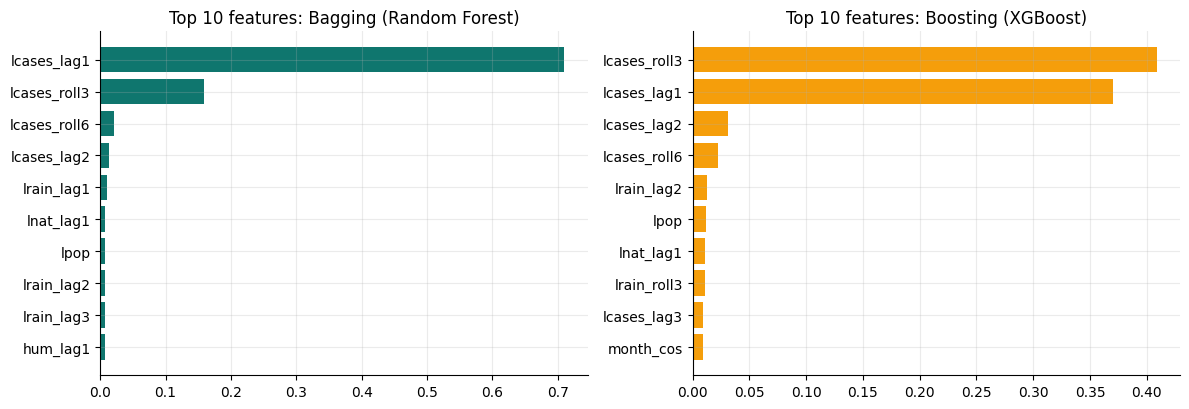

Stacking weights (blend of base-learner predictions): {'rf': np.float64(0.2246), 'xgb': np.float64(0.0187), 'ridge': np.float64(0.7672), 'knn': np.float64(0.0134)}


In [17]:
imp = {"rf": dict(zip(P.FEATURES, rf.feature_importances_.round(4))),
       "xgb": dict(zip(P.FEATURES, xgb.feature_importances_.round(4)))}
fig, axs = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, (k, c) in zip(axs, [("rf", "#0f766e"), ("xgb", "#f59e0b")]):
    s = pd.Series(imp[k]).sort_values().tail(10)
    ax.barh(s.index, s.values, color=c); ax.set_title(f"Top 10 features: {LABEL[k]}")
plt.tight_layout(); plt.show()
print("Stacking weights (blend of base-learner predictions):", stack.weights_)

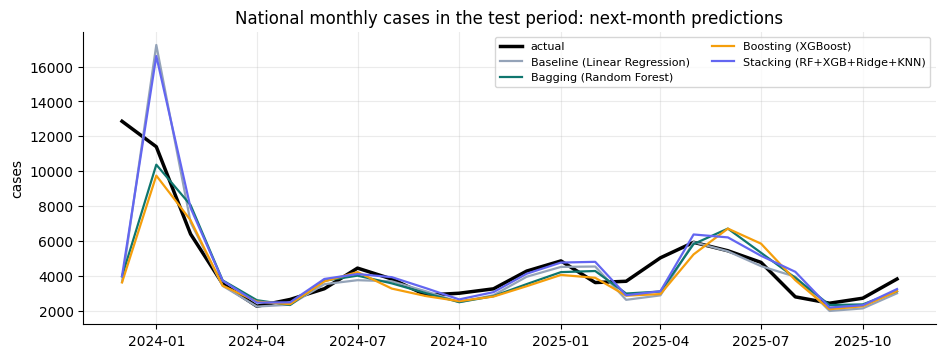

In [18]:
# Where does each model go wrong? national test-period curve
nat_act = test.groupby("month_start")["cases"].sum()
fig, ax = plt.subplots()
ax.plot(nat_act.index, nat_act.values, color="black", lw=2.5, label="actual")
for k, c in zip(models, ["#94a3b8", "#0f766e", "#f59e0b", "#6366f1"]):
    s = pd.Series(test_pred[k], index=test.index).groupby(test["month_start"]).sum()
    ax.plot(s.index, s.values, color=c, label=LABEL[k], lw=1.6)
ax.set(title="National monthly cases in the test period: next-month predictions", ylabel="cases"); ax.legend(ncol=2, fontsize=8)
plt.show()

## 12. Discussion: which approach performed best, and why

### Summary of the evidence

| | Baseline (Linear) | Bagging (RF) | Boosting (XGBoost) | Stacking |
|---|---|---|---|---|
| **Next-month**, district RMSE (cases) | 161.0 | 156.4 | 156.0 | **155.2** |
| **Next-month**, district MAE (cases) | 60.2 | 56.8 | **56.2** | 59.8 |
| **Next-month**, national MAE (cases) | **1,099** | 978 | 1,033 | 1,103 |
| **24 months ahead**, district RMSE | 246.6 | 215.1 | 220.1 | **201.8** |
| **24 months ahead**, national MAE | 2,507 | 1,715 | 1,823 | **1,423** |
| **24 months ahead**, national sMAPE | 68.0% | 36.5% | 40.2% | **27.8%** |

### Which approach performed best?

**Stacking is the best overall.** It has the lowest next-month district RMSE and wins every metric in the 24-month recursive test, which is the situation the dashboard's future forecast is actually in.

**For next-month accuracy the four models are practically tied.** District RMSE differs by only about 3.6% between the worst and best model, and the ranking changes with the metric (XGBoost has the best MAE, Random Forest the best national MAE, Stacking the best RMSE). Excluding the surge months (Dec 2023 - Feb 2024), the national MAE is 508 (baseline), 567 (RF), 625 (XGBoost) and 519 (stack), so in calm months even the plain linear model is hard to beat. We should not claim a clear winner from the one-step table alone.

### Why did the models behave this way?

1. **Next-month dengue is mostly "last month again".** The most important features are `lcases_lag1` and `lcases_roll3` (RF: 71% + 16% of importance, XGBoost: 37% + 41%). Because case counts are so autocorrelated, even a linear model captures most of the signal, which is why the baseline is competitive in calm months and the ensembles' gains are small. The trees add value mainly where relations are non-linear (district differences, the monsoon season, rainfall acting with a delay), which explains the 3 to 6% lower district MAE/RMSE and the better national R-squared (RF 0.40 vs baseline 0.16).

2. **Every model misses the Dec 2023 surge, and that dominates the national scores.** National cases jumped from about 3,600 to 12,900 in one month. All four models predicted roughly 3,600 to 4,000 for December 2023 because nothing in the lagged cases, weather or season signalled such a jump. This is an irreducible limit of a forecasting model that only sees the past, and it is why the national R-squared values are low even though district-level R-squared is about 0.7.

3. **Bagging vs boosting.** Random Forest averages many deep trees fitted on bootstrap samples, which lowers **variance**; XGBoost fits shallow trees sequentially to the previous errors, which lowers **bias**. Their cross-validated errors on the training data were almost identical (0.513 vs 0.517 log-MAE), and their test errors are within about 1% of each other at district level. With about 5,000 rows, strong autocorrelation and noisy weekly reporting, there is little systematic structure left for boosting to extract, so its extra flexibility buys little. XGBoost also fits the training data more tightly (in-sample district RMSE 134 vs 145 for RF) and is therefore slightly more exposed to noise.

4. **Why stacking wins when forecasting ahead.** In recursive forecasting each prediction becomes the next month's lag, so small errors compound. The tree models predict conditional averages and drift towards typical values (e.g. for May 2025 the baseline predicted about 1,500 cases and the trees about 2,800 against 5,900 actual). The stack's meta-learner put most weight on the **Ridge** learner (0.77), plus the Random Forest (0.22), and almost none on XGBoost (0.02) and KNN (0.01). This tells us that the linear learner's smooth seasonal-and-trend behaviour is the more reliable ingredient once predictions are fed back in, while the forest adds non-linear corrections; blending the two gave about 6% lower district RMSE than the best single ensemble (RF 215.1 vs 201.8) and a much lower national MAE (1,423 vs 1,715). Stacking works here because the base learners make *different* errors; if they had been similar, the blend would not have helped.

5. **The baseline is clearly worst when forecasting ahead** (national R-squared -0.67, sMAPE 68%): a purely linear model cannot represent the non-linear seasonal peaks, and its mistakes compound month after month.

### Honest limitations

* The test window is 24 months and contains a single surge, so small differences (especially in the one-step table) are indicative, not statistically conclusive.
* Differences between "calm-month" accuracy and "outbreak" accuracy are large: the models forecast **seasonality and trend**, not unforeseeable outbreaks.
* Future weather is replaced by historical monthly averages, so the forecast cannot anticipate an unusually wet or dry season.

## 13. Save everything for the dashboard
Predictions for the whole history (one-step-ahead) and the recursive backtest feed the *Past Predictions* page. For the future forecast, the four models are **re-fitted on all available data** (training + test) with the same settings, so that the most recent months are used.

In [19]:
# --- predictions over the whole history (models trained on the training period only) ---
allp = data[["district", "month_start", "cases"]].rename(columns={"cases": "actual"}).copy()
for k, m in models.items():
    allp[k] = one_step(data, m)
allp["split"] = np.where(allp["month_start"] <= cutoff, "train", "test")
allp.to_csv("../artifacts/predictions_onestep.csv", index=False)

bt = pd.concat([f.assign(model=k) for k, f in rec.items()], ignore_index=True)
bt.to_csv("../artifacts/backtest_recursive.csv", index=False)

# --- metrics file ---
best = min(res_one, key=lambda k: res_one[k]["district"]["RMSE"])
best_multi = min(res_multi, key=lambda k: res_multi[k]["district"]["RMSE"])
metrics_out = {
    "data_start": str(panel["month_start"].min().date()), "data_end": str(panel["month_start"].max().date()),
    "cutoff": str(cutoff.date()), "test_months": TEST_MONTHS,
    "n_train_rows": int(len(train)), "n_test_rows": int(len(test)),
    "labels": LABEL, "one_step": res_one, "multi_step": res_multi, "sigma": sigma,
    "best_model": best, "best_model_multistep": best_multi,
    "best_params": {"rf": rf_search.best_params_, "xgb": xgb_search.best_params_},
    "cv_mae_log": {"rf": float(-rf_search.best_score_), "xgb": float(-xgb_search.best_score_)},
    "stack_weights": {k: float(v) for k, v in stack.weights_.items()},
    "importance": {k: {f: float(x) for f, x in v.items()} for k, v in imp.items()},
}
json.dump(metrics_out, open("../artifacts/metrics.json", "w"), indent=2)
print("best (next-month RMSE):", best, "| best (24-month recursive RMSE):", best_multi)

best (next-month RMSE): stack | best (24-month recursive RMSE): stack


In [20]:
# --- refit on ALL rows for deployment ---
full_X, full_y, full_g = data[P.FEATURES], data["y"], data["month_idx"]
deploy = {
    "baseline": make_pipeline(StandardScaler(), LinearRegression()).fit(full_X, full_y),
    "rf": RandomForestRegressor(n_jobs=-1, random_state=SEED, **rf_search.best_params_).fit(full_X, full_y),
    "xgb": XGBRegressor(n_jobs=-1, random_state=SEED, tree_method="hist", **xgb_search.best_params_).fit(full_X, full_y),
}
rf, xgb = deploy["rf"], deploy["xgb"]            # make_stack() picks these up
deploy["stack"] = make_stack().fit(full_X, full_y, groups=full_g)
for k, m in deploy.items():
    joblib.dump(m, f"../models/deploy_{k}.joblib", compress=3)
joblib.dump(P.FEATURES, "../models/feature_columns.joblib")
import os
for f in sorted(os.listdir("../models")):
    print(f"{f:28s} {os.path.getsize('../models/'+f)/1e6:6.1f} MB")

deploy_baseline.joblib          0.0 MB
deploy_rf.joblib                3.5 MB
deploy_stack.joblib             8.3 MB
deploy_xgb.joblib               0.3 MB
feature_columns.joblib          0.0 MB


In [21]:
# sanity check: the deployed models forecast the next months
last_hist = panel
for k in ["baseline", "rf", "xgb", "stack"]:
    f = P.recursive_forecast(deploy[k], last_hist, 3)
    print(k, f.groupby("month_start")["pred"].sum().round(0).to_dict())

baseline {Timestamp('2025-12-01 00:00:00'): 4738.0, Timestamp('2026-01-01 00:00:00'): 4932.0, Timestamp('2026-02-01 00:00:00'): 3666.0}


rf {Timestamp('2025-12-01 00:00:00'): 4481.0, Timestamp('2026-01-01 00:00:00'): 4270.0, Timestamp('2026-02-01 00:00:00'): 3502.0}


xgb {Timestamp('2025-12-01 00:00:00'): 4550.0, Timestamp('2026-01-01 00:00:00'): 4213.0, Timestamp('2026-02-01 00:00:00'): 3502.0}


stack {Timestamp('2025-12-01 00:00:00'): 4977.0, Timestamp('2026-01-01 00:00:00'): 5379.0, Timestamp('2026-02-01 00:00:00'): 4257.0}


## 14. Conclusion and limitations
* The comparison above uses the same chronological test window, the same features and the same target transform for all four models.
* Forecasts several months ahead are recursive and use average weather, so they capture **seasonality and the current trend, not unforeseeable outbreaks**. The dashboard shows this with an uncertainty range that widens with the horizon.
* The test window is only 24 months and contains one surge, so differences between close models should be read as indicative rather than definitive.